# Homework09

Exercises to practice unsupervised learning with clustering

## Goals

- Get more practice with the ML flow: encode -> normalize -> train -> evaluate
- Understand the tradeoffs of modeling parameters
- Develop intuition for different clustering models and when to use them

### Setup

Run the following 2 cells to import all necessary libraries and helpers for this homework.

In [78]:
!wget -q "https://github.com/PSAM-5020-2026F-A/5020-utils/raw/main/src/data_utils.py" -O data_utils.py
!wget -q "https://github.com/PSAM-5020-2026F-A/5020-utils/raw/main/src/image_utils.py" -O image_utils.py
!wget -q "https://github.com/PSAM-5020-2026F-A/Homework/raw/main/html.tgz" -O html.tgz
!tar -xzf html.tgz


gzip: stdin: unexpected end of file
tar: Child returned status 1
tar: Error is not recoverable: exiting now


In [79]:
import json
import matplotlib.pyplot as plt
import pandas as pd

from os import listdir
from PIL import Image as PImage

from sklearn.preprocessing import OrdinalEncoder, StandardScaler
from sklearn.mixture import GaussianMixture
from sklearn.cluster import KMeans

from data_utils import balance_score, distance_score, silhouette_score, display_silhouette_plots
from data_utils import object_from_json_url

from image_utils import get_pixels, make_image

## Helmet Sizing

### Load Dataset

Let's load up the full [ANSUR](https://www.openlab.psu.edu/ansur2/) dataset that we looked at briefly in [Week 02](https://github.com/PSAM-5020-2026F-A/WK02) and then again in [Homework06](https://github.com/PSAM-5020-2026F-A/Homework06).

This is the dataset that has anthropometric information about U.S. Army personnel.

#### WARNING

Like we mentioned in class, this dataset is being used for these exercises due to the level of detail in the dataset and the rigorous process that was used in collecting the data.

This is a very specific dataset and should not be used to draw general conclusions about people, bodies, or anything else that is not related to the distribution of physical features of U.S. Army personnel.

In [80]:
# Load Dataset
ANSUR_FILE = "https://raw.githubusercontent.com/PSAM-5020-2026F-A/5020-utils/main/datasets/json/ansur.json"
ansur_data = object_from_json_url(ANSUR_FILE)

# Look at first 2 records
ansur_data[:2]

[{'age': 18,
  'gender': 'F',
  'height': 66,
  'weight': 135,
  'span': 1699,
  'stature': 1645,
  'ear': {'breadth': 30, 'length': 61, 'protrusion': 20},
  'foot': {'breadth': 97, 'length': 243},
  'hand': {'breadth': 78, 'length': 182, 'palm': 108},
  'head': {'height': 243, 'circumference': 557}},
 {'age': 30,
  'gender': 'M',
  'height': 68,
  'weight': 207,
  'span': 1749,
  'stature': 1715,
  'ear': {'breadth': 35, 'length': 63, 'protrusion': 17},
  'foot': {'breadth': 100, 'length': 252},
  'hand': {'breadth': 87, 'length': 184, 'palm': 114},
  'head': {'height': 238, 'circumference': 560}}]

Let's load it into a `DataFrame`, like last week.

In [81]:
# Read into DataFrame
ansur_df = pd.json_normalize(ansur_data)
ansur_df.head()

,age,gender,height,weight,span,stature,ear.breadth,ear.length,ear.protrusion,foot.breadth,foot.length,hand.breadth,hand.length,hand.palm,head.height,head.circumference
0,18,F,66,135,1699,1645,30,61,20,97,243,78,182,108,243,557
1,30,M,68,207,1749,1715,35,63,17,100,252,87,184,114,238,560
2,27,M,67,121,1684,1657,36,59,24,92,251,84,180,103,239,516
3,20,M,73,185,1878,1828,36,60,21,104,280,95,201,124,270,582
4,33,M,76,150,1977,1883,39,65,27,101,271,90,194,113,254,559


### Unsupervised Learning

Let's pretend we are designing next-generation helmets with embedded over-the-ear headphones and we want to have a few options for sizes.

We could use clustering to see if there is a number of clusters that we can divide our population into, so each size covers a similar portion of the population.

We can follow similar steps to regression to create a clustering model that uses features about head and ear sizes:

1. Load dataset (done! 🎉)
2. Encode label features as numbers
3. Normalize the data
4. Separate the feature variables we want to consider (done below)
5. Pick a clustering algorithm
6. Determine number of clusters
7. Cluster data
8. Interpret results

For step $5$, it's fine to just pick an algorithm ahead of time to see what happens, but feel free to experiment and plot results for multiple clustering methods.

In [82]:
## Encode non-numerical features

ansur_encoded_df = ansur_df.copy()
text_cols = ansur_encoded_df.select_dtypes(exclude="number").columns
encoder = OrdinalEncoder()
ansur_encoded_df[text_cols] = encoder.fit_transform(ansur_encoded_df[text_cols])

## Normalize the data

scaler = StandardScaler().set_output(transform="pandas")
ansur_scaled_df = scaler.fit_transform(ansur_encoded_df)

In [83]:
## Separate the features we want to consider
ansur_features = ansur_scaled_df[["head.height", "head.circumference", "ear.length", "ear.breadth", "ear.protrusion"]]

KMeans objective score: -17081.549208345088
KMeans distance score: 1.6517439809039303
KMeans silhouette score: 0.1928662619669502
KMeans balance score: 0.954375


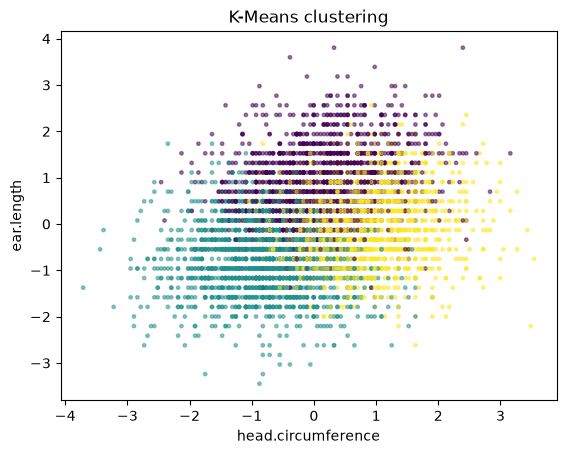

In [84]:
## Create Clustering model
n_clusters = 3
km_model = KMeans(n_clusters=n_clusters, random_state=1010)

## Run the model(s) on the data

km_predicted = km_model.fit_predict(ansur_features)

## Check errors

print("KMeans objective score:", km_model.score(ansur_features))
print("KMeans distance score:", distance_score(ansur_features, km_predicted))
print("KMeans silhouette score:", silhouette_score(ansur_features, km_predicted))
print("KMeans balance score:", balance_score(km_predicted))

## Plot clusters as function of 2 or 3 variables

plt.scatter(ansur_features["head.circumference"], ansur_features["ear.length"], c=km_predicted, marker='o', linestyle='', alpha=0.5, s=6)
plt.title("K-Means clustering")
plt.xlabel("head.circumference")
plt.ylabel("ear.length")
plt.show()

Gaussian likelihood score: -6.578970506044335
Gaussian distance score: 1.6714776708292671
Gaussian silhouette score: 0.1789162882262868
Gaussian balance score: 0.9624107142857143


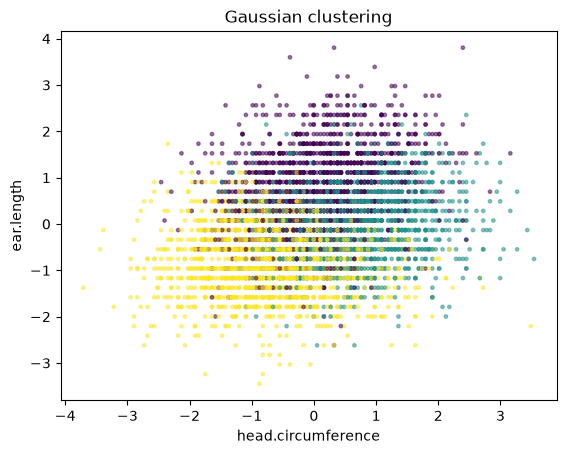

In [85]:
gc_model = GaussianMixture(n_components=n_clusters, random_state=101010)
gc_predicted = gc_model.fit_predict(ansur_features)

print("Gaussian likelihood score:", gc_model.score(ansur_features))
print("Gaussian distance score:", distance_score(ansur_features, gc_predicted))
print("Gaussian silhouette score:", silhouette_score(ansur_features, gc_predicted))
print("Gaussian balance score:", balance_score(gc_predicted))

plt.scatter(ansur_features["head.circumference"], ansur_features["ear.length"], c=gc_predicted, marker='o', linestyle='', alpha=0.5, s=6)
plt.title("Gaussian clustering")
plt.xlabel("head.circumference")
plt.ylabel("ear.length")
plt.show()

### Interpretation

<span style="color:hotpink;">
Which clustering algorithm did you choose?<br>
Did you try a different one?<br>
Do the clusters make sense ? Do they look balanced ?
</span>

I chose K-Means first, with 3 clusters, and I also tried Gaussian Mixture with 3 clusters to compare. The two models scored very similarly. K-Means had a distance score of 1.65 (Gaussian 1.67) and a silhouette score of 0.19 (Gaussian 0.18), so K-Means was slightly tighter and slightly better separated. Gaussian had a slightly higher balance score, 0.96 compared to 0.95. The differences are tiny, so neither algorithm is clearly better. The clusters do look balanced. Both balance scores are above 0.95, so each helmet size would cover a similar share of people.

## Figure out how many clusters

Experiment with the number of clusters to see if the initial choice makes sense.

The [WK09](https://github.com/PSAM-5020-2026F-A/WK09) notebook had a for loop that can be used to plot errors versus number of clusters.

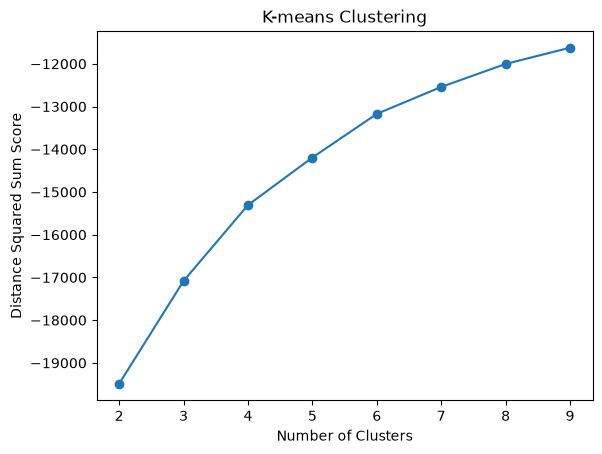

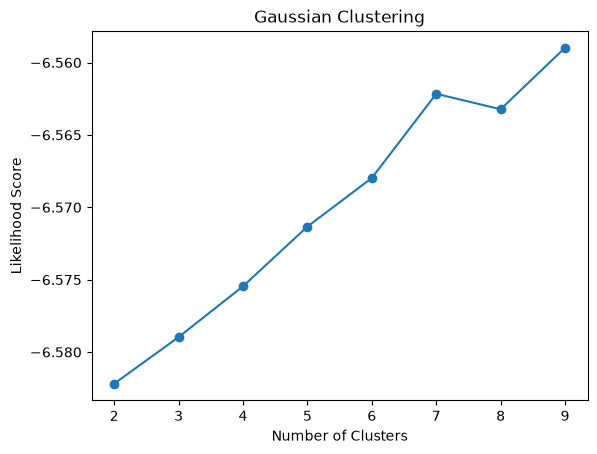

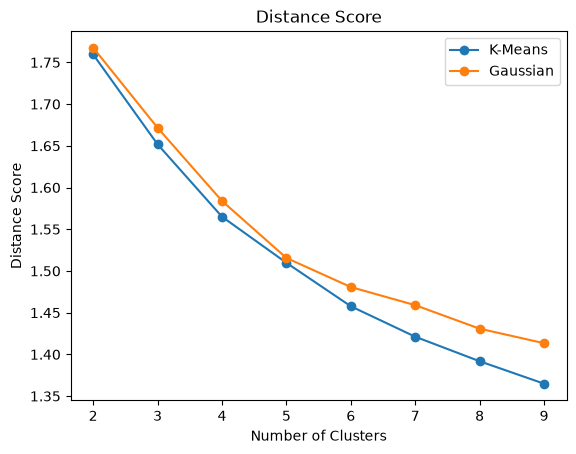

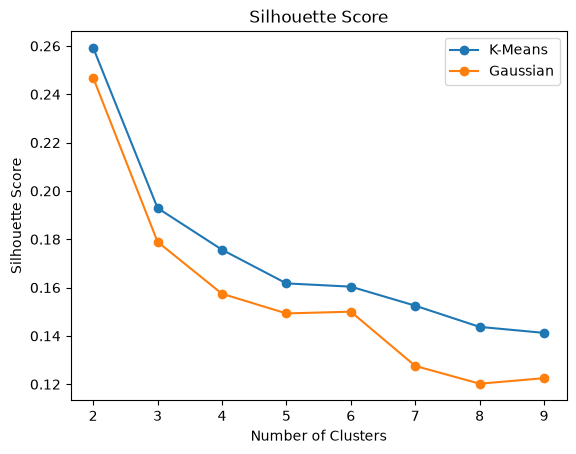

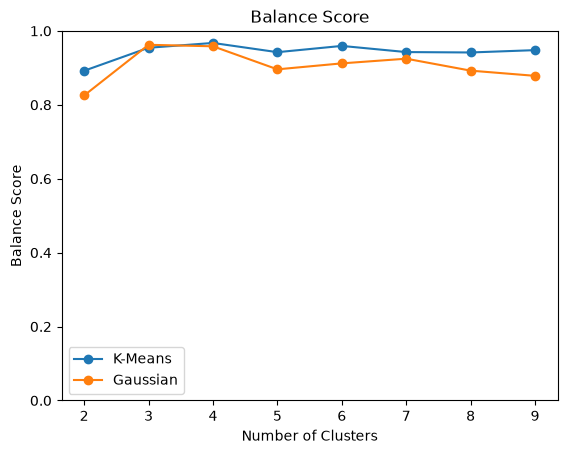

In [86]:
## Plot errors and pick how many cluster

## Plot errors and pick how many cluster
num_clusters = list(range(2,10))

km_score_scores = []
gc_score_scores = []
km_distance_scores = []
gc_distance_scores = []
km_silhouette_scores = []
gc_silhouette_scores = []
km_balance_scores = []
gc_balance_scores = []

for n in num_clusters:
  km = KMeans(n_clusters=n)
  gc = GaussianMixture(n_components=n)
  km_pred = km.fit_predict(ansur_features)
  gc_pred = gc.fit_predict(ansur_features)
  km_score_scores.append(km.score(ansur_features))
  gc_score_scores.append(gc.score(ansur_features))
  km_distance_scores.append(distance_score(ansur_features, km_pred))
  gc_distance_scores.append(distance_score(ansur_features, gc_pred))
  km_silhouette_scores.append(silhouette_score(ansur_features, km_pred))
  gc_silhouette_scores.append(silhouette_score(ansur_features, gc_pred))
  km_balance_scores.append(balance_score(km_pred))
  gc_balance_scores.append(balance_score(gc_pred))

plt.plot(num_clusters, km_score_scores, marker='o')
plt.xlabel("Number of Clusters")
plt.ylabel("Distance Squared Sum Score")
plt.title("K-means Clustering")
plt.show()

plt.plot(num_clusters, gc_score_scores, marker='o')
plt.xlabel("Number of Clusters")
plt.ylabel("Likelihood Score")
plt.title("Gaussian Clustering")
plt.show()

plt.plot(num_clusters, km_distance_scores, marker='o', label="K-Means")
plt.plot(num_clusters, gc_distance_scores, marker='o', label="Gaussian")
plt.xlabel("Number of Clusters")
plt.ylabel("Distance Score")
plt.title("Distance Score")
plt.legend()
plt.show()

plt.plot(num_clusters, km_silhouette_scores, marker='o', label="K-Means")
plt.plot(num_clusters, gc_silhouette_scores, marker='o', label="Gaussian")
plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score")
plt.legend()
plt.show()

plt.plot(num_clusters, km_balance_scores, marker='o', label="K-Means")
plt.plot(num_clusters, gc_balance_scores, marker='o', label="Gaussian")
plt.xlabel("Number of Clusters")
plt.ylabel("Balance Score")
plt.title("Balance Score")
plt.ylim([0, 1])
plt.legend()
plt.show()

### Interpretation

<span style="color:hotpink;">
Based on the graphs of errors versus number of clusters, does it look like we should change the initial number of clusters ?<br>
How many clusters should we use ? Why ?
</span>

For K-Means, the distance squared sum score rises quickly from 2 to 4 clusters (about -19,000 to -15,000) and then flattens, adding only small gains per cluster after that, so there is an elbow around 4. The distance score also drops fastest up to 4 clusters and then declines slowly and steadily without another sharp bend. The Gaussian likelihood score changes very little overall (about -6.582 to -6.560), so it doesn’t give a clear reason to pick any number.

The silhouette score is highest at 2 clusters (about 0.26 for K-Means), drops sharply at 3 (0.19), and then keeps decreasing slowly as clusters are added. Every value is low, which means the groups overlap a lot, and more clusters make this worse. K-Means has a higher silhouette than Gaussian for almost every number of clusters. 

I think I would use 4 or a bit higher clusters with K-Means. Four is where the error curve has its elbow and where balance is best.

### Revise Number of Clusters.

Re-run with the new number of clusters and plot the data in $2D$ or $3D$.

This can be the same graph as above.

KMeans objective score: -15310.036144502343
KMeans distance score: 1.564941318187274
KMeans silhouette score: 0.17667343968328705
KMeans balance score: 0.9754761904761905
Gaussian likelihood score: -6.575092657534716
Gaussian distance score: 1.5843372334350818
Gaussian silhouette score: 0.1588147836953086
Gaussian balance score: 0.9883333333333333


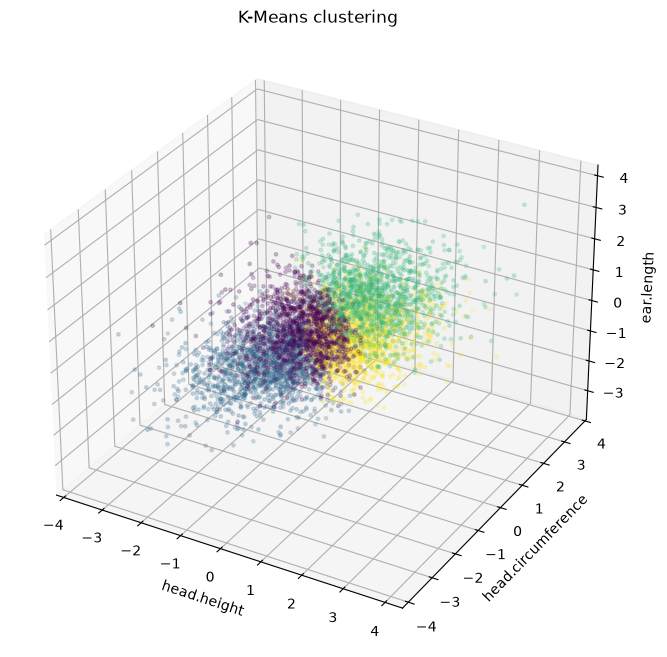

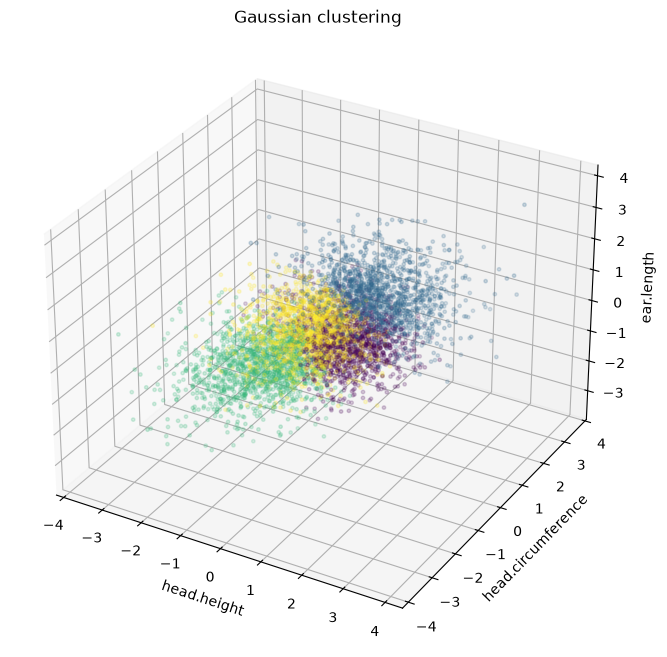

In [87]:
## Re-run clustering with final number of clusters
n_clusters = 4
km_model = KMeans(n_clusters=n_clusters, random_state=1010)
gc_model = GaussianMixture(n_components=n_clusters, random_state=101010)

## Run the model on the training data
km_predicted = km_model.fit_predict(ansur_features)
gc_predicted = gc_model.fit_predict(ansur_features)

## Check errors
print("KMeans objective score:", km_model.score(ansur_features))
print("KMeans distance score:", distance_score(ansur_features, km_predicted))
print("KMeans silhouette score:", silhouette_score(ansur_features, km_predicted))
print("KMeans balance score:", balance_score(km_predicted))

print("Gaussian likelihood score:", gc_model.score(ansur_features))
print("Gaussian distance score:", distance_score(ansur_features, gc_predicted))
print("Gaussian silhouette score:", silhouette_score(ansur_features, gc_predicted))
print("Gaussian balance score:", balance_score(gc_predicted))

## Plot in 3D
fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(projection='3d')

ax.scatter(ansur_features["head.height"], ansur_features["head.circumference"], ansur_features["ear.length"], c=km_predicted, marker='o', linestyle='', alpha=0.5, s=6)

ax.set_title("K-Means clustering")
ax.set_xlabel("head.height")
ax.set_ylabel("head.circumference")
ax.set_zlabel("ear.length")
plt.show()

fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(projection='3d')

ax.scatter(ansur_features["head.height"], ansur_features["head.circumference"], ansur_features["ear.length"], c=gc_predicted, marker='o', linestyle='', alpha=0.5, s=6)

ax.set_title("Gaussian clustering")
ax.set_xlabel("head.height")
ax.set_ylabel("head.circumference")
ax.set_zlabel("ear.length")
plt.show()

### Interpretation

<span style="color:hotpink;">
Do these look better than the original number of clusters?
</span>

Yes, mostly. The 4-cluster results look somewhat better than the original 3 clusters, although they are not better on every score.

Compared to 3 clusters, the K-Means objective score improved from about -17,082 to -15,310, and its distance score dropped from 1.652 to 1.565, so members are closer to their cluster centers. The K-Means balance score improved from 0.954 to 0.975. Gaussian improved the same way: its likelihood score went from -6.579 to -6.575, its distance score from 1.672 to 1.584, and its balance score from 0.962 to 0.988. Both models now have very balanced clusters, so each helmet size would fit a similar share of people. The only score that got worse is the silhouette score, which dropped from 0.193 to 0.177 for K-Means and from 0.179 to 0.159 for Gaussian. That means the groups overlap a bit more with 4 clusters.

## Image Organization

We have a dataset of about $600$ flower images that we might want to classify by species... eventually.

What we want to do first is take a look at all of the images and see what kind of images we have, what kind of colors our flowers have and see if there's any other visual information that could help us classify these images later.

We'll see how to use clustering and distances to organize our images by color to create a visualization that we cna use to get to know our dataset.

### Load Dataset

The following cell downloads the dataset:

In [88]:
!wget -qO- https://github.com/PSAM-5020-2026F-A/5020-utils/releases/latest/download/flowers.tar.gz | tar xz

Then, we can take a look at a few of the images:

In [89]:
IMG_DIR = "./data/image/flowers"

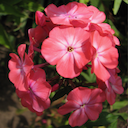

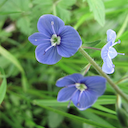

In [90]:
display(PImage.open(f"{IMG_DIR}/00_001.png"))
display(PImage.open(f"{IMG_DIR}/15_001.png"))

### Find Representative Colors

The overall process for organizing our images by color will be something like this:

1. Iterate over all files in the `data/image/flowers` directory, open each image file and treat it as a dataset
   1. Load image into a `DataFrame` where each pixel is a row and R,G,B values are columns/features
   2. Cluster into $2$ - $16$ colors
   3. Pick $3$ or $4$ representative colors
   4. Store image filenames and their representative colors in a Python object
2. Once all images have been processed we can order our dataset by different color characteristics: white to black, red to blue, hue value, brightness

### One Image

Let's step through the process of getting representative colors for one image, and then we can repeat this in a loop to process all of the flower images.

#### Open Image

The `PIL` library does all the work here:

In [91]:
# Open image
fname = "00_001.png"
pimg = PImage.open(f"{IMG_DIR}/{fname}").convert("RGB")

#### Put into `DataFrame`

We get the pixels and make a dataset/`DataFrame` out of them:

In [92]:
# Load into DataFrame
pxs = get_pixels(pimg)
pxs_df = pd.DataFrame(pxs, columns=["R", "G", "B"])

#### Cluster colors

Create a clustering object, cluster colors into $8$ clusters with `fit_predict()` and take a look at our color palette (`cluster_centers_`):

In [93]:
# TODO: Create Clustering object
img_model = KMeans(n_clusters=16)

# TODO: Cluster by color
px_clusters = img_model.fit_predict(pxs_df)

# TODO: Take a look at the color palette (cluster_centers_)
img_model.cluster_centers_

array([[100.92326733,  23.51856436,  29.46905941],
       [236.37848606,  95.14840637, 115.17629482],
       [ 95.87638889,  73.09166667,  49.49583333],
       [247.0988806 , 181.49253731, 206.54104478],
       [214.73310023,  69.3030303 ,  88.06526807],
       [ 13.28493151,  15.05114155,  10.80045662],
       [245.30691824, 141.63647799, 169.92075472],
       [145.03884372,  46.64227642,  65.13730804],
       [ 58.64877301,  55.39263804,  30.15797546],
       [173.45818182,  77.22909091, 103.28      ],
       [128.93901345,  31.84484305,  43.35784753],
       [124.83886256, 136.18009479,  65.86729858],
       [ 33.20672478,  33.3071814 ,  19.25487754],
       [ 77.9251497 ,  95.9745509 ,  37.68263473],
       [244.20250195, 118.80609851, 141.06645817],
       [187.70481928,  44.51084337,  61.18554217]])

#### Checkpoint

<span style="color:hotpink;">
Does anything stand out about the colors?
</span>

Yes, a few things stand out. Most of the palette is made of reds and pinks, which look like the flower. Five of the 8 colors are in that family, and they go from light pink [246, 164, 192] through bright pink [241, 112, 134] and strong red [202, 59, 78] to a dusty rose [158, 83, 93] and a dark red [129, 34, 46]. These are mostly the same color at different brightness levels, which is probably the lighter and shadowed parts of the petals.

The other 3 colors are dark and earthy: near-black [20, 21, 14], dark brown [53, 46, 27] and a dark olive [88, 87, 44]. These are likely the background, soil and leaves.

#### Reconstruct Image

Since we're only doing one image for now, let's take a look at the clustering result.

This is like in the lecture notebook. We'll start with an empty pixel array and as we iterate through the `DataFrame` of cluster ids we append the corresponding colors to it.

In [94]:
# TODO: create empty pixel array
pxs_post = []

# TODO: iterate through resulting list of cluster ids
color_centers = [[round(r), round(g), round(b)] for r,g,b in img_model.cluster_centers_]

for gidx in px_clusters:
  
# TODO: append corresponding color value to pixel array
  pxs_post.append(color_centers[gidx])

Now we can look at the image. If this next cell gives errors about using `float` values in images, just make sure the pixel values that are being appended above are all whole number `int` values.

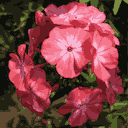

In [95]:
display(make_image(pxs_post, width=pimg.size[0]))

#### Checkpoint

<span style="color:hotpink;">
How does changing the number of clusters affect the resulting image?<br>Try some lower values like <code>2</code> and <code>4</code>, and also some higher ones like <code>12</code> and <code>16</code>. Take a look at a different image.
</span>

With 8 clusters, the flower still looks recognizable, but it looks like a poster or a cartoon. The petals have flat patches of light pink, pink and red instead of smooth shading, and the background is flattened into a few dark green, olive and black areas.

With 2 clusters, the image is reduced to just two colors: a flat dusty pink for the flower and a dark brown for everything else. The overall shape of the flower is still visible, but all the detail is gone. The lighter centers and shading in the petals, the green leaves and the shadows between the flowers all disappear, and parts of the smaller petals blend into the background.

With 16 clusters, the image is much closer to the original. The petals have a smooth range of pinks, reds and light pink highlights, so the center of each flower and the folds of the petals are visible again. The background also gets several shades of green, olive and dark brown, so the leaves can be seen separately from the shadows. It still looks slightly posterized, with visible patches of flat color, but it is hard to tell from a real photo at a glance.

#### Pick Colors

Ok, we have some representative colors for our images. We should keep more than one color, but maybe we don't have to keep $12$.

If we put our predictions in a `DataFrame` we can use the `value_counts()` function of our `DataFrame` to see how many pixels are represented by each of our cluster colors, and get the result ordered by most frequent to less frequent cluster id:

In [96]:
# cluster ids and pixel counts, ordered by descending counts
px_clusters_df = pd.DataFrame(px_clusters, columns=["clusters"])
ccounts = px_clusters_df["clusters"].value_counts()
display(ccounts)

clusters
12    2414
5     2184
8     1305
14    1279
10    1116
7     1096
1     1003
4      860
15     832
0      818
6      794
2      723
13     666
9      547
3      536
11     211
Name: count, dtype: int64

Since what we are really trying to do here is get some information about the colors of the flowers present in our images, and given the type of images we have, we can start by assuming that the flower colors will be in the top-$4$ clusters returned by `value_counts()`.

We can revisit this assumption later. We might also want to add some filters here to ignore sky and vegetation colors (blues and greens) and only keep flower colors.

For now, let's just grab the top $4$ colors from `value_counts()`, remembering we want to keep their rounded `int` values and not the default `float` values in `cluster_centers_`.

In [97]:
file_info = {
  "filename": fname,
  "colors": []
}

# TODO: go through ccounts.index and get corresponding colors for each clusters
color_centers = [[round(r), round(g), round(b)] for r,g,b in img_model.cluster_centers_]

for cidx in ccounts.index[:4]:
  # TODO: add top-4 colors to the "colors" key of the file_color_info object
  file_info["colors"].append(color_centers[cidx])

In [98]:
display(file_info)

{'filename': '00_001.png',
 'colors': [[33, 33, 19], [13, 15, 11], [59, 55, 30], [244, 119, 141]]}

#### Checkpoint

<span style="color:hotpink;">
Why might we want to cluster into <code>8</code> or even <code>12</code> colors when in the end we're only keeping <code>4</code>?
</span>

We might cluster into 8 or even 12 colors, when we only keep 4, because more clusters give the model room to separate similar shades, so each cluster color is a more accurate color.

### Iterate and Cluster

We've processed one image, now let's process $600$... for-loops FTW!

We'll need to loop through all of the images in our directory and repeat the process above for each one of them.

We can create a function that takes a filename as input and returns the top-$4$ colors for that image, or... we can just put all of the clustering logic in the body of a for loop. Whichever is easiest.

Let's get started.

In [99]:
# list of all files in the flowers directory
flower_files = sorted([f for f in listdir(IMG_DIR) if f.endswith(".png")])

Here's the loop. In the end we want our `file_colors` list to have objects that have a filename and $4$ colors associated with each filename. Something like:

```py
[
  {
    "filename": "00_001.png",
    "colors": [[12,44,12], [112,144,62],  [12,84,112], [212,144,102]]
  },
  {
    "filename": "00_002.png",
    "colors": [[22,24,28], [112,114,122], [128,200,2], [250,240,230]]
  },
  ...
]
```

This can take a while to run (up to a minute for $600$ images). We can use slicing to test our logic on a subset of `flower_files` before processing all $600$ images.

In [100]:
# List to keep colors for each file
file_colors = []

# TODO: get colors for each image
for fname in flower_files:
  # TODO: add logic here
  pimg = PImage.open(f"{IMG_DIR}/{fname}").convert("RGB")
  pxs = get_pixels(pimg)
  pxs_df = pd.DataFrame(pxs, columns=["R", "G", "B"])

  img_model = KMeans(n_clusters=8)
  px_clusters = img_model.fit_predict(pxs_df)

  px_clusters_df = pd.DataFrame(px_clusters, columns=["clusters"])
  ccounts = px_clusters_df["clusters"].value_counts()

  color_centers = [[round(r), round(g), round(b)] for r,g,b in img_model.cluster_centers_]

  colors = []
  for cidx in ccounts.index[:4]:
    colors.append(color_centers[cidx])

  # TODO: add filename+colors object to list of objects
  file_colors.append({"filename": fname, "colors": colors})

#### Order Images (almost)

We have a list with objects that keep track of filenames and representative colors. We could create a `DataFrame` or csv dataset with these, but let's go ahead and just use this directly in this format.

What we want to do is re-order our list of objects, but using a `key` function that takes each object's colors into consideration.

We'll look into how to do this dynamically later, but for now let's order our images by something like _brightness_. It's _like_ brightness because what we'll do is measure how close each image is to the white color `(255,255,255)`.

We'll need some helper functions first:

- `color_distance()`: takes $2$ colors and returns the distance between them
- `min_color_distance()`: given a reference color and a list of colors, returns the distance between the reference color and the closest color in the list

In [101]:
# TODO: implement function that returns distance between two colors
def color_distance(c0, c1):
  # TODO: add logic here
  return ((c0[0] - c1[0])**2 + (c0[1] - c1[1])**2 + (c0[2] - c1[2])**2) ** 0.5

Some tests for the `color_distance()` function:

In [102]:
# Some tests for the color_distance() function
print(color_distance([0,0,0], [255,255,255]), "should be", 255*3**.5)
print(color_distance([0,100,0], [100,100,0]), "should be", 100)
print(color_distance([55,222,120], [91,51,192]), "should be", 189)
print(color_distance([147,207,246], [87,57,50]), "should be", 254)
print(color_distance([12,250,126], [112,10,195]), "should be", 269)
print(color_distance([106,71,61], [105,136,100]), "should be", 75.81)

441.6729559300637 should be 441.67295593006367
100.0 should be 100
189.0 should be 189
254.0 should be 254
269.0 should be 269
75.80897044545586 should be 75.81


In [103]:
# TODO: implement function that returns minimum distance between a reference color and colors from a list
def min_color_distance(ref_color, color_list):
  # TODO: add logic here
  distances = []
  for c in color_list:
    distances.append(color_distance(ref_color, c))
  return min(distances)

Three tests for the `min_color_distance()` function:

In [104]:
# Some tests for the color_distance() function
print(min_color_distance([0,0,0], [[255,255,255],[0,100,0],[100,100,0],[58,58,58]]), "should be", 100)
print(min_color_distance([0,0,0], [[255,255,255],[0,100,0],[100,100,0],[58,57,58]]), "should be", 99.88)
print(min_color_distance([91,51,192], [[147,207,246],[87,57,50],[12,250,126],[112,10,195]]), "should be", 46.16)

100.0 should be 100
99.88493379884676 should be 99.88
46.16275555033516 should be 46.16


#### Order Images (for real now)

Alright. We have a function that can be used to order our images by their distance to a given color.

Let's order our images by how close they are to the brightest color `(255,255,255)`. We'll define a `key` function that, given an object from our `file_colors` list, returns how close that image is to the color `(255,255,255)`.

In [105]:
# TODO: implement function that returns how close our image is to the color white
def by_bright_dist(A):
  # TODO: add logic here
  return min_color_distance([255, 255, 255], A["colors"])

Order the list and write out a `JSON` file with the image order.

In [106]:
file_colors_sorted = sorted(file_colors, key=by_bright_dist)

In [107]:
files_sorted = [A["filename"] for A in file_colors_sorted]

with open("./data/flower_order.json", "w") as ofp:
  json.dump(files_sorted, ofp)

### Viewing Results

We can check the results by running a webserver and looking at a simple web page that orders the images according to the resulting `JSON` file from above.

We'll make use of the [`Live Server`](https://marketplace.visualstudio.com/items?itemName=ritwickdey.LiveServer) VSCode extension.

We can start the server by clicking on the "_Go Live_" button towards the right hand side of the bar at the very bottom of our text editor:

<img src="https://psam-5020-2026f-a.github.io/5020-imgs/HW09/go_live.jpg" width="600px">

Clicking the "_Go Live_" button in Codespace should open up a new tab with a plain html navigation view of our repository. Clicking on the `html/` directory should open up a web page with all of the flower images. If not, you can use your Codespace url to try to find the web server address.

If your Codespace url is something like:<br>`https://mango-special-giggle-v6v7asd322f7p6.github.dev/`

Then, the webserver should be running at:<br>`https://mango-special-giggle-v6v7asd322f7p6-5500.app.github.dev/`

### Review, Contemplate, Experiment

Yes, images with white parts are towards the beginning, but the images towards the end aren't necessarily the ones with dark flowers, but are the ones that have all of their representative colors farthest away from white `(255,255,255)`, which includes very saturated colors/images.

A couple of interesting experiments here could be:
- Decrease the number of clusters or the number of colors kept after clustering.
- Use different colors as the reference for the distance functions. For example, create `by_gold_dist()` or `by_purple_dist()` functions to use as the `key` for sorting.
- Order the list of cluster colors by [hue](https://stackoverflow.com/questions/23090019/fastest-formula-to-get-hue-from-rgb). This can be a bit tricky to get right because some colors, like white, black and gray, don't have a unique value for hue, but depend on other aspects of the color, like saturation and lightness, to be well-defined.

In [108]:
# TODO: experiment with number of clusters, number of colors, reference colors or hue distances
def by_purple_dist(A):
  return min_color_distance([128, 0, 128], A["colors"])

file_colors_sorted = sorted(file_colors, key=by_purple_dist)
files_sorted = [A["filename"] for A in file_colors_sorted]

with open("./data/flower_order.json", "w") as ofp:
  json.dump(files_sorted, ofp)

### Interpretation

<span style="color:hotpink;">
What did you try ? What happened ?
</span>

<span style="color:hotpink;">EDIT THIS CELL WITH ANSWER</span>

### Conclusion

It's challenging to define a set of functions that will perfectly order our flowers by color without first having to define very specific color values for filtering and corner-cases. At a high-level, we can imagine that this is because color is a $3$-dimensional value, and we're using it to organize our images into a single-dimensional order.

The beginning of our ordering is usually pretty good, since there's only one way for a color to be _close_ to our reference color, but the ordering gets less consistent towards the end because there are many different ways for a color to be _far_ from the reference color.

Next week we'll see a very powerful technique that, amongst other things, will help us get around this kind of "_dimensionality mismatch_".